In [1]:

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


In [2]:
taxis = sns.load_dataset("taxis")

print(taxis.head())

               pickup             dropoff  passengers  distance  fare   tip  \
0 2019-03-23 20:21:09 2019-03-23 20:27:24           1      1.60   7.0  2.15   
1 2019-03-04 16:11:55 2019-03-04 16:19:00           1      0.79   5.0  0.00   
2 2019-03-27 17:53:01 2019-03-27 18:00:25           1      1.37   7.5  2.36   
3 2019-03-10 01:23:59 2019-03-10 01:49:51           1      7.70  27.0  6.15   
4 2019-03-30 13:27:42 2019-03-30 13:37:14           3      2.16   9.0  1.10   

   tolls  total   color      payment            pickup_zone  \
0    0.0  12.95  yellow  credit card        Lenox Hill West   
1    0.0   9.30  yellow         cash  Upper West Side South   
2    0.0  14.16  yellow  credit card          Alphabet City   
3    0.0  36.95  yellow  credit card              Hudson Sq   
4    0.0  13.40  yellow  credit card           Midtown East   

            dropoff_zone pickup_borough dropoff_borough  
0    UN/Turtle Bay South      Manhattan       Manhattan  
1  Upper West Side South      

In [3]:
print("dimension : " , taxis.shape)

dimension :  (6433, 14)


In [4]:
taxis["pickup"] = pd.to_datetime(taxis["pickup"])
taxis["dropoff"] = pd.to_datetime(taxis["dropoff"])

In [6]:
print("premiere course : ", taxis["pickup"].min())
print("derniere course : " ,taxis["pickup"].max())


premiere course :  2019-02-28 23:29:03
derniere course :  2019-03-31 23:43:45


In [8]:
taxis_index = taxis.set_index("pickup")

courses_par_jour = taxis_index.resample("D").size()

ca_par_jour = taxis_index.resample("D")["total"].sum()

print("NOMBRE DE COURSE PAR JOUR : ", courses_par_jour)

print("\nChiffre d'affaires par jour :" , ca_par_jour)




NOMBRE DE COURSE PAR JOUR :  pickup
2019-02-28      1
2019-03-01    241
2019-03-02    198
2019-03-03    169
2019-03-04    171
2019-03-05    228
2019-03-06    257
2019-03-07    218
2019-03-08    235
2019-03-09    204
2019-03-10    185
2019-03-11    209
2019-03-12    218
2019-03-13    244
2019-03-14    260
2019-03-15    201
2019-03-16    220
2019-03-17    178
2019-03-18    173
2019-03-19    201
2019-03-20    233
2019-03-21    221
2019-03-22    229
2019-03-23    209
2019-03-24    149
2019-03-25    155
2019-03-26    178
2019-03-27    232
2019-03-28    205
2019-03-29    209
2019-03-30    215
2019-03-31    187
Freq: D, dtype: int64

Chiffre d'affaires par jour : pickup
2019-02-28       6.30
2019-03-01    4213.83
2019-03-02    3319.02
2019-03-03    3027.32
2019-03-04    3269.08
2019-03-05    4377.38
2019-03-06    4673.61
2019-03-07    4115.70
2019-03-08    4524.21
2019-03-09    3785.80
2019-03-10    3198.69
2019-03-11    4021.26
2019-03-12    3875.80
2019-03-13    4868.06
2019-03-14    4742.5

In [9]:
bilan_journalier = pd.DataFrame({
    "nombre_courses" : courses_par_jour,
    "chiffre_affaires": ca_par_jour
})

print(bilan_journalier.head(10))

            nombre_courses  chiffre_affaires
pickup                                      
2019-02-28               1              6.30
2019-03-01             241           4213.83
2019-03-02             198           3319.02
2019-03-03             169           3027.32
2019-03-04             171           3269.08
2019-03-05             228           4377.38
2019-03-06             257           4673.61
2019-03-07             218           4115.70
2019-03-08             235           4524.21
2019-03-09             204           3785.80


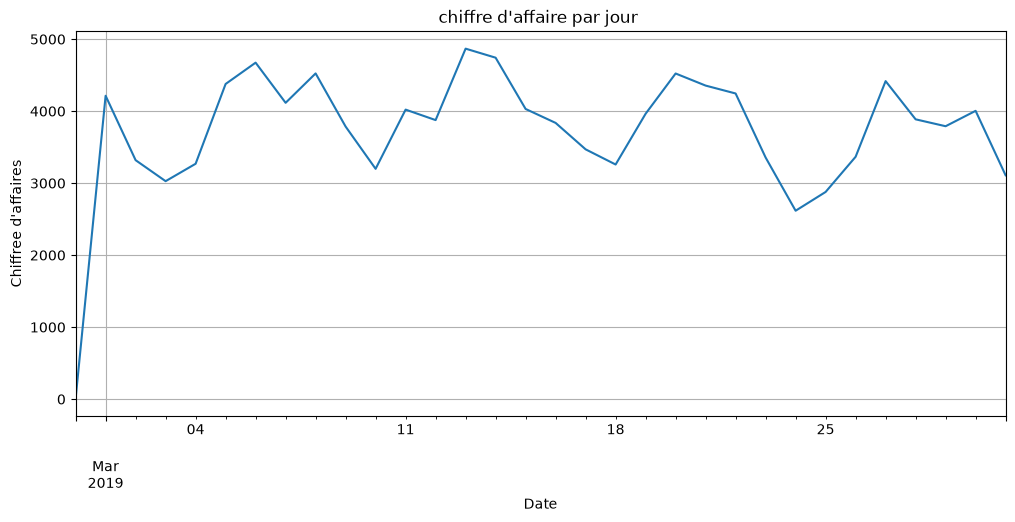

In [10]:
ca_par_jour.plot(figsize=(12,5), title="chiffre d'affaire par jour ")
plt.xlabel("Date")
plt.ylabel("Chiffree d'affaires")
plt.grid()
plt.show()

In [11]:
taxis["heure"] = taxis["pickup"].dt.hour

courses_par_heure = taxis["heure"].value_counts().sort_index()

heure_plus_chargee = courses_par_heure.idxmax()
nombre_max_courses = courses_par_heure.max()

print("Heure la plus chargee : " , heure_plus_chargee , "h")
print("Nombre de courses : " , nombre_max_courses)

Heure la plus chargee :  18 h
Nombre de courses :  417


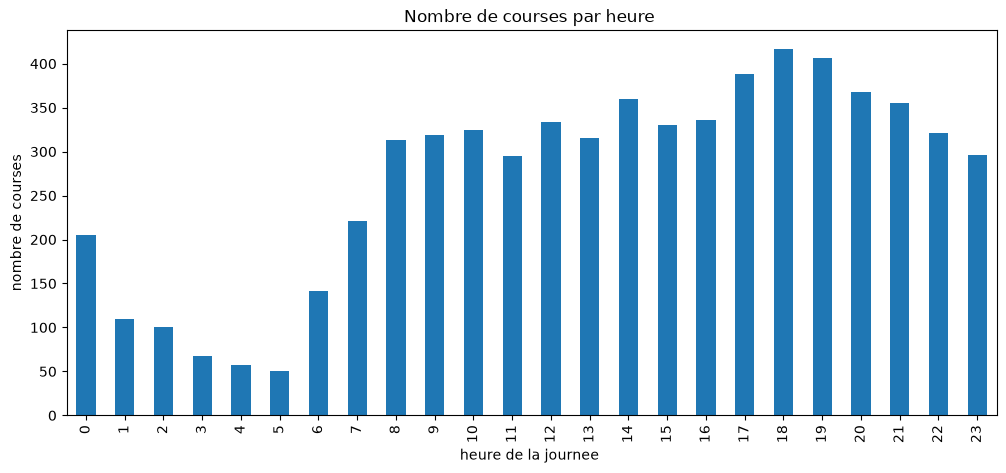

In [12]:
courses_par_heure.plot(
    kind="bar",
    figsize=(12, 5),
    title = "Nombre de courses par heure "
)

plt.xlabel("heure de la journee ")
plt.ylabel("nombre de courses")
plt.show()

In [14]:

taxis["jour_semaine"] = taxis["pickup"].dt.day_name()


pourboire_moyen = taxis.groupby("jour_semaine")["tip"].mean()

ordre_jours = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

pourboire_moyen = pourboire_moyen.reindex(ordre_jours)

print("Pourboire moyen par jour :")
print(pourboire_moyen)


jour_max = pourboire_moyen.idxmax()
montant_max = pourboire_moyen.max()

print("\nJour avec le pourboire moyen le plus élevé :", jour_max)
print("Pourboire moyen :", round(montant_max, 2))


Pourboire moyen par jour :
jour_semaine
Monday       2.027316
Tuesday      2.001370
Wednesday    2.087329
Thursday     2.062177
Friday       1.980108
Saturday     1.815143
Sunday       1.908710
Name: tip, dtype: float64

Jour avec le pourboire moyen le plus élevé : Wednesday
Pourboire moyen : 2.09


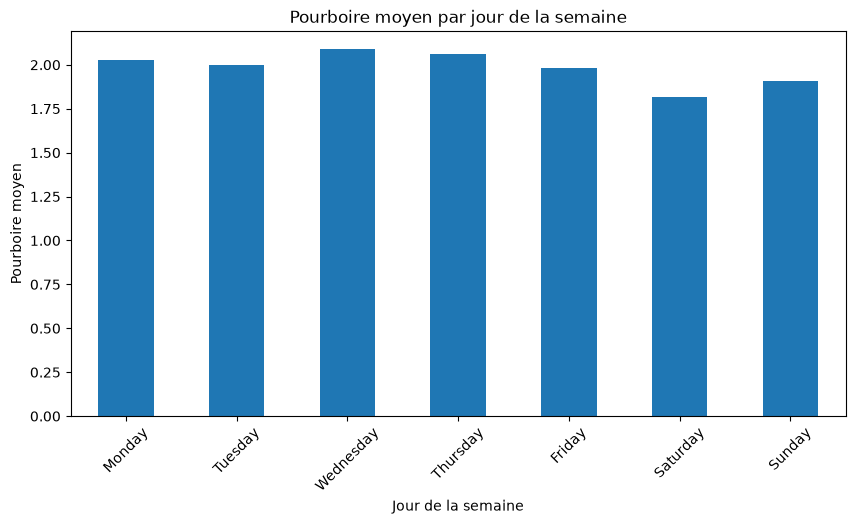

In [15]:

pourboire_moyen.plot(
    kind="bar",
    figsize=(10, 5),
    title="Pourboire moyen par jour de la semaine"
)

plt.xlabel("Jour de la semaine")
plt.ylabel("Pourboire moyen")
plt.xticks(rotation=45)
plt.show()


In [16]:

taxis["duree_minutes"] = (
    taxis["dropoff"] - taxis["pickup"]
).dt.total_seconds() / 60

print(taxis[["pickup", "dropoff", "duree_minutes"]].head())


               pickup             dropoff  duree_minutes
0 2019-03-23 20:21:09 2019-03-23 20:27:24       6.250000
1 2019-03-04 16:11:55 2019-03-04 16:19:00       7.083333
2 2019-03-27 17:53:01 2019-03-27 18:00:25       7.400000
3 2019-03-10 01:23:59 2019-03-10 01:49:51      25.866667
4 2019-03-30 13:27:42 2019-03-30 13:37:14       9.533333


In [17]:


durees_negatives = taxis["duree_minutes"] < 0
durees_trop_longues = taxis["duree_minutes"] > 180

print("Durées négatives :", durees_negatives.sum())
print("Durées supérieures à 3 heures :", durees_trop_longues.sum())

anomalies = taxis[durees_negatives | durees_trop_longues]

print(anomalies[["pickup", "dropoff", "duree_minutes"]])


Durées négatives : 0
Durées supérieures à 3 heures : 0
Empty DataFrame
Columns: [pickup, dropoff, duree_minutes]
Index: []


In [18]:


masque_valide = (
    taxis["duree_minutes"].ge(0)
    & taxis["duree_minutes"].le(180)
    & taxis["duree_minutes"].notna()
)

taxis_valides = taxis[masque_valide].copy()

print("Nombre de courses initial :", len(taxis))
print("Nombre de courses valides :", len(taxis_valides))
print("Nombre de courses écartées :", len(taxis) - len(taxis_valides))

# Statistiques des durées valides
print(taxis_valides["duree_minutes"].describe())


Nombre de courses initial : 6433
Nombre de courses valides : 6433
Nombre de courses écartées : 0
count    6433.000000
mean       14.349617
std        11.643892
min         0.000000
25%         6.500000
50%        10.900000
75%        18.516667
max       107.666667
Name: duree_minutes, dtype: float64


In [ ]:

taxis["heure"] = taxis["pickup"].dt.hour
taxis["jour_semaine"] = taxis["pickup"].dt.day_name()

ca_par_jour = (
    taxis.set_index("pickup") 
    .resample("D")["total"]
    .sum()
)

ca_moyenne_7j = ca_par_jour.rolling(7).mean()


print(ca_par_jour.head(10))
print(ca_moyenne_7j.head(10))


pickup
2019-02-28       6.30
2019-03-01    4213.83
2019-03-02    3319.02
2019-03-03    3027.32
2019-03-04    3269.08
2019-03-05    4377.38
2019-03-06    4673.61
2019-03-07    4115.70
2019-03-08    4524.21
2019-03-09    3785.80
Freq: D, Name: total, dtype: float64
pickup
2019-02-28            NaN
2019-03-01            NaN
2019-03-02            NaN
2019-03-03            NaN
2019-03-04            NaN
2019-03-05            NaN
2019-03-06    3269.505714
2019-03-07    3856.562857
2019-03-08    3900.902857
2019-03-09    3967.585714
Freq: D, Name: total, dtype: float64
